# **NYC Airbnb Accommodation Analysis**
## **CA2 Strategic Thinking**

1. Business Understanding and Project Plan
2. Data Loading and Understanding
3. Data Quality Assessment
4. Data Cleaning and Feature Engineering
5. Descriptive Statistics
6. Exploratory Data Visualisation
7. Inferential Statistics
8. Findings and Limitations
9. Export and Reproducibility

### **Import the libraries**

In [1]:
from pathlib import Path
import sys
import importlib.metadata as metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

OUTPUT = Path("/content/ca2_outputs")
FIGURES = OUTPUT / "figures"

OUTPUT.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)

print("Python version:", sys.version)
print("Output folder:", OUTPUT)

Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Output folder: /content/ca2_outputs


### **Upload and load the dataset**

In [2]:
from google.colab import files

uploaded = files.upload()

Saving AB_NYC_2019.csv to AB_NYC_2019.csv


In [3]:
DATA_PATH = Path("/content/AB_NYC_2019.csv")

df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Rows: 48895
Columns: 16


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


**Inspect data quality**

In [4]:
df.info()

quality_table = pd.DataFrame({
    "Data type": df.dtypes.astype(str),
    "Missing values": df.isna().sum(),
    "Missing percentage": (df.isna().mean() * 100).round(2),
    "Unique values": df.nunique()
})

display(quality_table)

print("Duplicate rows:", df.duplicated().sum())
print("Duplicate listing IDs:", df["id"].duplicated().sum())

display(df["neighbourhood_group"].value_counts())
display(df["room_type"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

,Data type,Missing values,Missing percentage,Unique values
id,int64,0,0.00,48895
name,object,16,0.03,47905
host_id,int64,0,0.00,37457
host_name,object,21,0.04,11452
neighbourhood_group,object,0,0.00,5
neighbourhood,object,0,0.00,221
latitude,float64,0,0.00,19048
longitude,float64,0,0.00,14718
room_type,object,0,0.00,3
price,int64,0,0.00,674


Duplicate rows: 0
Duplicate listing IDs: 0


,count
neighbourhood_group,
Manhattan,21661
Brooklyn,20104
Queens,5666
Bronx,1091
Staten Island,373


,count
room_type,
Entire home/apt,25409
Private room,22326
Shared room,1160


In [5]:
checks = pd.Series({
    "Zero prices": df["price"].eq(0).sum(),
    "Negative prices": df["price"].lt(0).sum(),
    "Non-positive minimum nights": df["minimum_nights"].le(0).sum(),
    "Minimum stays above 365 nights": df["minimum_nights"].gt(365).sum(),
    "Availability outside 0–365":
        (~df["availability_365"].between(0, 365)).sum(),
    "Zero availability": df["availability_365"].eq(0).sum(),
    "Negative review counts": df["number_of_reviews"].lt(0).sum()
})

display(checks.to_frame("Count"))

,Count
Zero prices,11
Negative prices,0
Non-positive minimum nights,0
Minimum stays above 365 nights,14
Availability outside 0–365,0
Zero availability,17533
Negative review counts,0


**Clean the dataset**

In [6]:
# Preserve the original dataset in df_raw.
df = df_raw.copy()

# Convert review dates without inventing missing dates.
original_dates = df["last_review"].copy()

df["last_review"] = pd.to_datetime(
    df["last_review"],
    errors="coerce"
)

invalid_dates = (
    original_dates.notna() & df["last_review"].isna()
).sum()

# Record review status and original missingness.
df["has_reviews"] = df["number_of_reviews"].gt(0)
df["review_rate_was_missing"] = df["reviews_per_month"].isna()

# Fill missing review rates only for listings with zero reviews.
zero_review_mask = (
    df["reviews_per_month"].isna()
    & df["number_of_reviews"].eq(0)
)

df.loc[zero_review_mask, "reviews_per_month"] = 0

# Flag records rather than deleting them indiscriminately.
df["valid_price"] = df["price"].gt(0)
df["unusual_minimum_stay"] = df["minimum_nights"].gt(365)

# Create a separate subset for positive-price analysis.
df_price = df.loc[df["valid_price"]].copy()

print("Invalid non-missing dates:", invalid_dates)
print("Review rates filled:", zero_review_mask.sum())
print("Full dataset rows:", len(df))
print("Positive-price analysis rows:", len(df_price))

Invalid non-missing dates: 0
Review rates filled: 10052
Full dataset rows: 48895
Positive-price analysis rows: 48884


In [7]:
cleaning_log = pd.DataFrame([
    {
        "Action": "Convert latest-review dates",
        "Affected rows": int(invalid_dates),
        "Reason": "Invalid non-missing dates converted to missing dates"
    },
    {
        "Action": "Fill missing review rates with zero",
        "Affected rows": int(zero_review_mask.sum()),
        "Reason": "Only applied where total reviews equal zero"
    },
    {
        "Action": "Flag non-positive prices",
        "Affected rows": int((~df["valid_price"]).sum()),
        "Reason": "Exclude from price analysis; retain in full dataset"
    },
    {
        "Action": "Flag minimum stays above 365 nights",
        "Affected rows": int(df["unusual_minimum_stay"].sum()),
        "Reason": "Investigate unusual restrictions without automatic deletion"
    }
])

display(cleaning_log)

,Action,Affected rows,Reason
0,Convert latest-review dates,0,Invalid non-missing dates converted to missing...
1,Fill missing review rates with zero,10052,Only applied where total reviews equal zero
2,Flag non-positive prices,11,Exclude from price analysis; retain in full da...
3,Flag minimum stays above 365 nights,14,Investigate unusual restrictions without autom...


**Create useful features**

In [8]:
df["availability_fraction"] = df["availability_365"] / 365

df["log_price"] = np.nan
positive_price_mask = df["valid_price"]

df.loc[positive_price_mask, "log_price"] = np.log(
    df.loc[positive_price_mask, "price"]
)

df_price = df.loc[positive_price_mask].copy()

display(df[[
    "price",
    "valid_price",
    "log_price",
    "has_reviews",
    "availability_fraction",
    "unusual_minimum_stay"
]].head())

,price,valid_price,log_price,has_reviews,availability_fraction,unusual_minimum_stay
0,149,True,5.003946,True,1.000000,False
1,225,True,5.416100,True,0.972603,False
2,150,True,5.010635,False,1.000000,False
3,89,True,4.488636,True,0.531507,False
4,80,True,4.382027,True,0.000000,False


## **Calculate descriptive statistics**

In [9]:
numeric_columns = [
    "price",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "availability_365"
]

display(df[numeric_columns].describe())

borough_summary = (
    df_price.groupby("neighbourhood_group")
    .agg(
        listings=("id", "count"),
        mean_price=("price", "mean"),
        median_price=("price", "median"),
        median_availability=("availability_365", "median")
    )
    .round(2)
)

room_summary = (
    df_price.groupby("room_type")
    .agg(
        listings=("id", "count"),
        mean_price=("price", "mean"),
        median_price=("price", "median"),
        median_reviews=("number_of_reviews", "median")
    )
    .round(2)
)

display(borough_summary)
display(room_summary)

,price,minimum_nights,number_of_reviews,reviews_per_month,availability_365
count,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000
mean,152.720687,7.029962,23.274466,1.090910,112.781327
std,240.154170,20.510550,44.550582,1.597283,131.622289
min,0.000000,1.000000,0.000000,0.000000,0.000000
25%,69.000000,1.000000,1.000000,0.040000,0.000000
50%,106.000000,3.000000,5.000000,0.370000,45.000000
75%,175.000000,5.000000,24.000000,1.580000,227.000000
max,10000.000000,1250.000000,629.000000,58.500000,365.000000


,listings,mean_price,median_price,median_availability
neighbourhood_group,,,,
Bronx,1090,87.58,65.0,148.0
Brooklyn,20095,124.44,90.0,28.0
Manhattan,21660,196.88,150.0,36.0
Queens,5666,99.52,75.0,98.0
Staten Island,373,114.81,75.0,219.0


,listings,mean_price,median_price,median_reviews
room_type,,,,
Entire home/apt,25407,211.81,160.0,5.0
Private room,22319,89.81,70.0,5.0
Shared room,1158,70.25,45.0,4.0


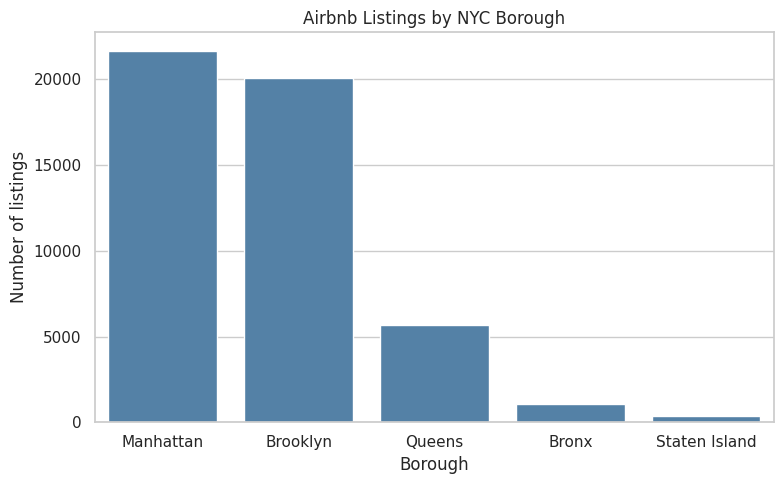

In [10]:
plt.figure(figsize=(8, 5))

order = df["neighbourhood_group"].value_counts().index

sns.countplot(
    data=df,
    x="neighbourhood_group",
    order=order,
    color="steelblue"
)

plt.title("Airbnb Listings by NYC Borough")
plt.xlabel("Borough")
plt.ylabel("Number of listings")
plt.tight_layout()

plt.savefig(FIGURES / "01_listings_by_borough.png", dpi=300)
plt.show()

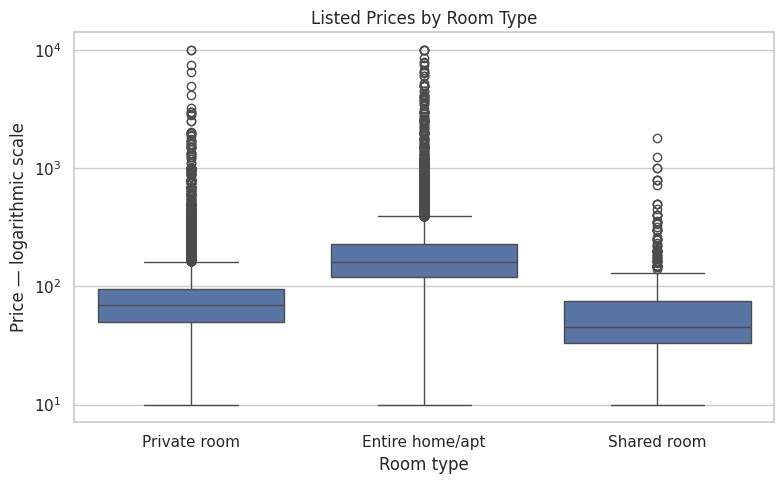

In [11]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_price,
    x="room_type",
    y="price"
)

plt.yscale("log")
plt.title("Listed Prices by Room Type")
plt.xlabel("Room type")
plt.ylabel("Price — logarithmic scale")
plt.tight_layout()

plt.savefig(FIGURES / "02_price_by_room_type.png", dpi=300)
plt.show()

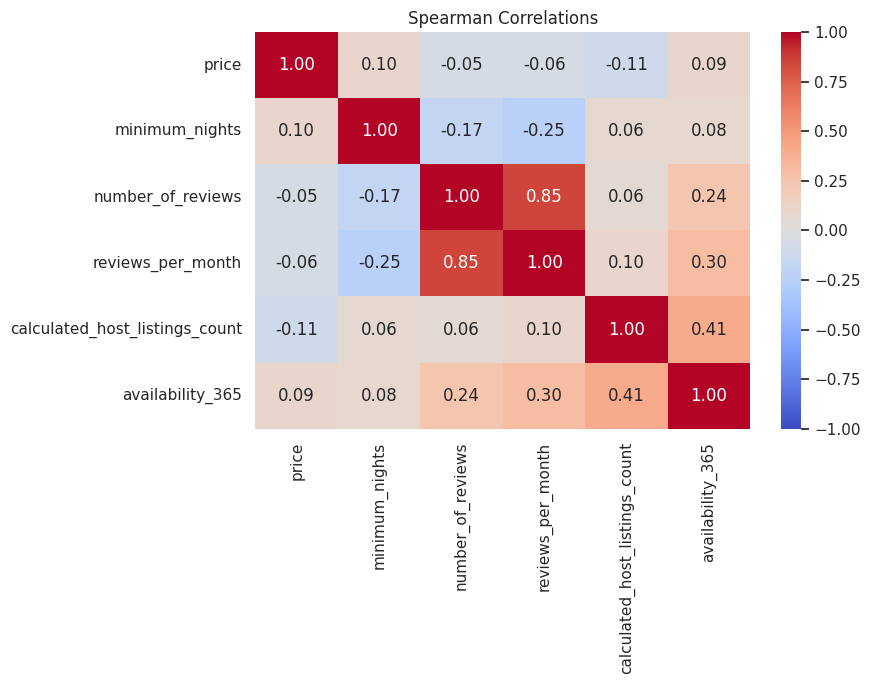

In [12]:
corr_columns = [
    "price",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365"
]

correlation = df_price[corr_columns].corr(method="spearman")

plt.figure(figsize=(9, 7))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Spearman Correlations")
plt.tight_layout()

plt.savefig(FIGURES / "03_spearman_correlations.png", dpi=300)
plt.show()

## **inferential statistics**

In [13]:
room_groups = [
    group["price"].to_numpy()
    for _, group in df_price.groupby("room_type")
]

h_statistic, p_value = stats.kruskal(*room_groups)

n = len(df_price)
k = len(room_groups)

epsilon_squared = max(
    0,
    (h_statistic - k + 1) / (n - k)
)

print(f"Kruskal–Wallis H: {h_statistic:.4f}")
print(f"P-value: {p_value:.6g}")
print(f"Approximate epsilon-squared: {epsilon_squared:.4f}")

Kruskal–Wallis H: 22414.8385
P-value: 0
Approximate epsilon-squared: 0.4585


In [14]:
# Use reviewed listings to avoid conflating missing-rate imputation
# with observed review intensity.
reviewed = df_price.loc[
    df_price["has_reviews"],
    ["price", "reviews_per_month"]
].dropna()

rho, spearman_p = stats.spearmanr(
    reviewed["price"],
    reviewed["reviews_per_month"]
)

print("Reviewed listings analysed:", len(reviewed))
print(f"Spearman correlation: {rho:.4f}")
print(f"P-value: {spearman_p:.6g}")

Reviewed listings analysed: 38833
Spearman correlation: -0.0185
P-value: 0.000268716


**Export the cleaned data and supporting tables**

In [15]:
df.to_csv(OUTPUT / "AB_NYC_2019_cleaned.csv", index=False)

quality_table.to_csv(OUTPUT / "data_quality_summary.csv")
cleaning_log.to_csv(OUTPUT / "cleaning_log.csv", index=False)

borough_summary.to_csv(OUTPUT / "borough_summary.csv")
room_summary.to_csv(OUTPUT / "room_type_summary.csv")

test_results = pd.DataFrame([
    {
        "Test": "Kruskal-Wallis: price by room type",
        "Statistic": h_statistic,
        "P_value": p_value,
        "Effect_measure": "Approximate epsilon-squared",
        "Effect_value": epsilon_squared
    },
    {
        "Test": "Spearman: price and review rate among reviewed listings",
        "Statistic": rho,
        "P_value": spearman_p,
        "Effect_measure": "Spearman rho",
        "Effect_value": rho
    }
])

test_results.to_csv(
    OUTPUT / "statistical_test_results.csv",
    index=False
)

packages = ["pandas", "numpy", "matplotlib", "seaborn", "scipy"]

requirements = "\n".join(
    f"{package}=={metadata.version(package)}"
    for package in packages
)

(OUTPUT / "requirements.txt").write_text(requirements)

print("Saved files:")
for path in sorted(OUTPUT.rglob("*")):
    if path.is_file():
        print(path.relative_to(OUTPUT))

Saved files:
AB_NYC_2019_cleaned.csv
borough_summary.csv
cleaning_log.csv
data_quality_summary.csv
figures/01_listings_by_borough.png
figures/02_price_by_room_type.png
figures/03_spearman_correlations.png
requirements.txt
room_type_summary.csv
statistical_test_results.csv


**Validate the completed notebook**

In [16]:
assert len(df) == len(df_raw), "Unexpected change in row count."
assert df["id"].is_unique, "Listing IDs are not unique."
assert df["availability_365"].between(0, 365).all()
assert df_price["price"].gt(0).all()

assert df.loc[
    zero_review_mask, "reviews_per_month"
].eq(0).all()

print("Validation checks passed.")

Validation checks passed.


In [17]:
files.download(str(OUTPUT / "AB_NYC_2019_cleaned.csv"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>